In [2]:
import os
from dotenv import load_dotenv
load_dotenv()
import langchain

print(langchain.__version__)
from langchain.agents import create_agent
from langchain_google_genai import ChatGoogleGenerativeAI

1.3.16


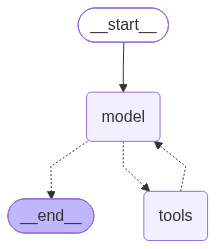

In [3]:
def get_weather(city:str)-> str:
    """get weather for a city """
    return f"the weather of the {city} is sunny  "
llm= ChatGoogleGenerativeAI(model="gemini-2.5-flash",temperature=0.7)

agent=create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="you are a helpful assitant",
    
    
)
agent


In [4]:
#running the agent 
response=agent.invoke({"messages":[{"role":"user","content":"what's the current weather update in the new york "}]})
response["messages"][-1].content


'The weather in New York is sunny.'

In [5]:
agent.invoke({"messages":"whats the weather in the india"})

{'messages': [HumanMessage(content='whats the weather in the india', additional_kwargs={}, response_metadata={}, id='6049f453-855a-4951-9021-71dfabb4c754'),
  AIMessage(content=[{'type': 'text', 'text': 'India is a country, I can not search weather for a country. Please provide a city.', 'extras': {'signature': 'CvADARFNMg8eUI72qgg1US/Tdr8kKZihK9M4YZ3EgL0oOUJAC7HWYh/fdPSmNEpcKKmfWn+BAYrtwPgpCfdgaanj4PLcdr17AmJpRKLm6hEmcq9YInSdqnMvPE26kdsGYH1SfzjuX+i9KAqzkvqCxrSyry9kNZuP4B96RpqBzuQRp7WR9nKtlI3IxRd0sbms4/+tws43+hsbhicR/qby9tWPxBW8uAbLeqBBO/UYFf6p0NSLJoAf8b5RDXiblfnbMnTl4pQGFqQh6PLzmH77DVBDkAtYpmJWAbGpgNi4/mToz9kQ49iq9VXj1CD1AtQUX73UYM5lKJY5+7IMn+2v/OkM9oYPHh/DFLNGCGwbZYmOQZeSasDWqSi0aHe2TIJnLvBQlFP4wDVOZiIYyrh/0g720enSfRMF+l7FyEcBZ3FDnPWEQ+VA48v3Z4OH4Kg35v+pU+GFot+NwfH2Pw2ggsiVXvnEexA2ReR/VFhXKYr5J1oa0KkyJus+ziOWo1bAC17vHt+iTzEPdyk26JmxW5ivMDIgcdjaDislU4qKVj1ZGKJqlgzo75SECN45W3b2Ihc26RKcL43YFjovi1duWsxvqHidC4mvlttunGqnxmq3+BvcFDnJLJrlktUORE3L1ut3Ju4ljfs5UR4VgWeTfxr7mg=='}}], additional_k

integrating llm from other services 


In [6]:
from langchain.chat_models import init_chat_model
model=init_chat_model("gemini-2.5-flash",model_provider="google_genai")
response=model.invoke("how are u ")
response.content

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


"I'm doing well, thank you for asking!\n\nAs an AI, I don't have feelings or physical states, but I'm operating perfectly and ready to assist you.\n\nHow are you today?"

there are 2 ways of calling or integrating model 

1st one is by init_chat_model and 

2nd one we use is langchain.goggle_genai import chatgooglegenrative one 

**STREAMING AND BATCH**

STREAMING

most models can stream their outputs while its being genrated .by displaying the output progressively

In [10]:
model.invoke("write me a poem about the moon")
##but we can stream its output as well by calling the stream method of the model object. This will return a generator that yields the output as it is generated.


AIMessage(content="A silver orb, it starts its gentle rise,\nAcross the velvet canvas of the skies.\nA silent watcher, draped in pearly light,\nThe ancient queen of every star-filled night.\n\nNo fiery sun, no blazing, golden might,\nBut cool serenity, a soft, pale light.\nFrom sliver thin, a graceful, curving smile,\nTo perfect disk, it changes all the while.\n\nIt pulls the ocean, whispers to the tide,\nA silent guardian, where the shadows hide.\nThe lover's plea, the poet's quiet sigh,\nReflected in a tear, or soulful eye.\n\nThrough ancient myths and tales of old it gleams,\nA silent witness to a million dreams.\nWith craters deep, and mountains stark and high,\nIt hangs aloof within the boundless sky.\n\nIt lights the path for wanderers astray,\nAnd chases fears of darkness far away.\nA constant friend, though distant and so far,\nThe tranquil beacon, brighter than a star.\n\nSo let us gaze upon its gentle face,\nAnd find a solace in its quiet grace.\nThe moon, eternal, timeless, 

In [11]:
for chunk in model.stream("write me a poem about the moon"):
    print(chunk.content,end="")

A silent watcher, pale and grand,
It climbs the velvet, inky sky,
A silver disc in night's soft hand,
Where countless, tiny star-gems lie.

It casts a gentle, ghostly gleam,
On sleeping forests, still and deep,
Reflecting in the flowing stream,
While weary mortals softly sleep.

From slender crescent, sharp and bright,
To full orb, round and luminous,
It journeys through the endless night,
A constant guide, mysterious.

It pulls the tides with unseen might,
And whispers secrets to the breeze,
A beacon in the fading light,
That dances through the ancient trees.

A timeless muse, a dreamers' friend,
It lights the path for those who roam,
A beauty that will never end,
Our solitary, silent home.

**Batch**

batch is the collection off independent request to a model can significatly imporve performance and reduce cost as the processig can be done in parallel

In [12]:
responses=model.batch(["write a poem about the sun","write a poem about the moon","write a poem about the stars"], config={"temperature":0.7,"max_concurrency":5})
for response in responses:
    print(response.content)

A golden orb, in skies so high,
You wake the world with gentle grace,
A silent promise in the sky,
And banish shadows from their place.

From distant core, a burning might,
A furnace grand, of ancient fire,
You pour forth warmth, and banish night,
Fulfilling every world's desire.

The giver of all vibrant green,
The lifeblood pulsing through the vine,
A silent, vital, solar queen,
Whose energy makes all things shine.

You rise each morn, a steadfast friend,
And journey slow across the blue,
Until the day begins to end,
And twilight paints a softer hue.

Your gentle kiss upon the skin,
A comfort felt, a joyful art,
A radiant warmth that dwells within,
And stirs the beat of every heart.

A star you are, our nearest star,
A giant furnace, burning bright,
Though millions of miles you are afar,
You fill our world with glorious light.

So praise the Sun, a constant fire,
The silent watcher, strong and true,
Our planet's hope, our soul's desire,
Forever vibrant, ever new.
A silent pearl in ve